In [2]:
import cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Librerias importadas correctamente")

Librerias importadas correctamente


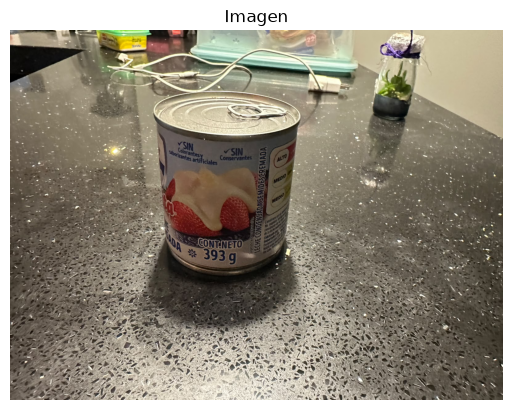

In [3]:
ruta_imagen = "images/lechcon34.jpeg"
imagen = cv2.imread(ruta_imagen)
if imagen is None:
    raise FileNotFoundError("No se encontro la imagen")

imagen_rgb= cv2.cvtColor(imagen,cv2.COLOR_BGR2RGB)
plt.imshow(imagen_rgb)
plt.title("Imagen")
plt.axis("off")
plt.show()


In [11]:
def histograma(eje, gris, titulo, color="#42A5F5"):
    eje.hist(gris.ravel(), bins=256, range=(0, 256), color=color)
    eje.set_title(titulo)
    eje.set_xlim(0, 255)
    eje.set_yticks([])
    
def mostrar(imagenes, titulos, cmap=None, ancho=4):
    fig, ejes = plt.subplots(1, len(imagenes), figsize=(ancho * len(imagenes), ancho))
    for eje, im, t in zip(np.atleast_1d(ejes), imagenes, titulos):
        if im.ndim == 2:
            fijo = im.dtype == np.uint8
            eje.imshow(im, cmap=cmap or "gray", vmin=0 if fijo else None, vmax=255 if fijo else None)
        else:
            eje.imshow(im)
        eje.set_title(t)
        eje.axis("off")
    plt.tight_layout()
    plt.show()


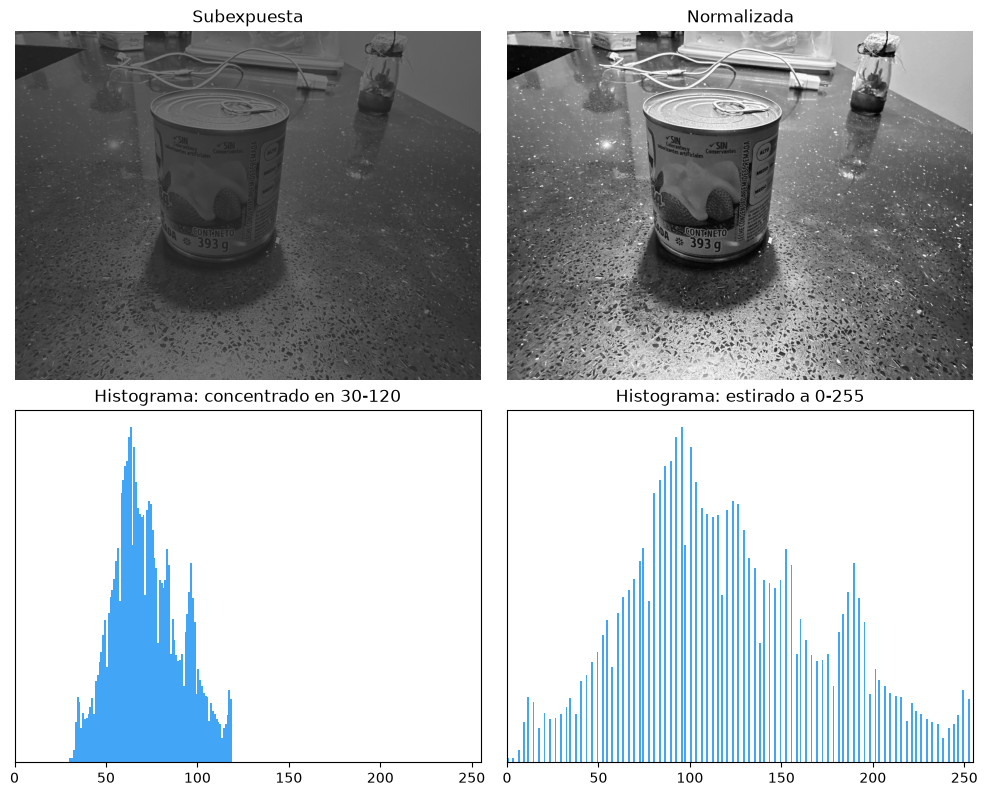

In [9]:
np.random.seed(42)
gris = cv2.cvtColor(imagen_rgb,cv2.COLOR_RGB2GRAY)
subexpuesta = (gris * 0.35 + 30).astype(np.uint8)

minimo, maximo = int(subexpuesta.min()), int(subexpuesta.max())
manual = ((subexpuesta.astype(float) - minimo) / (maximo - minimo) * 255).astype(np.uint8)
opencv = cv2.normalize(subexpuesta, None, 0, 255, cv2.NORM_MINMAX)

fig, ejes = plt.subplots(2, 2, figsize=(10, 8))
ejes[0, 0].imshow(subexpuesta, cmap="gray", vmin=0, vmax=255)
ejes[0, 0].set_title("Subexpuesta")
ejes[0, 1].imshow(opencv, cmap="gray", vmin=0, vmax=255)
ejes[0, 1].set_title("Normalizada")
histograma(ejes[1, 0], subexpuesta, "Histograma: concentrado en 30-120")
histograma(ejes[1, 1], opencv, "Histograma: estirado a 0-255")
for e in ejes[0]:
    e.axis("off")
plt.tight_layout()
plt.show()


Diferencia máxima ecualización manual vs cv2.equalizeHist: 0


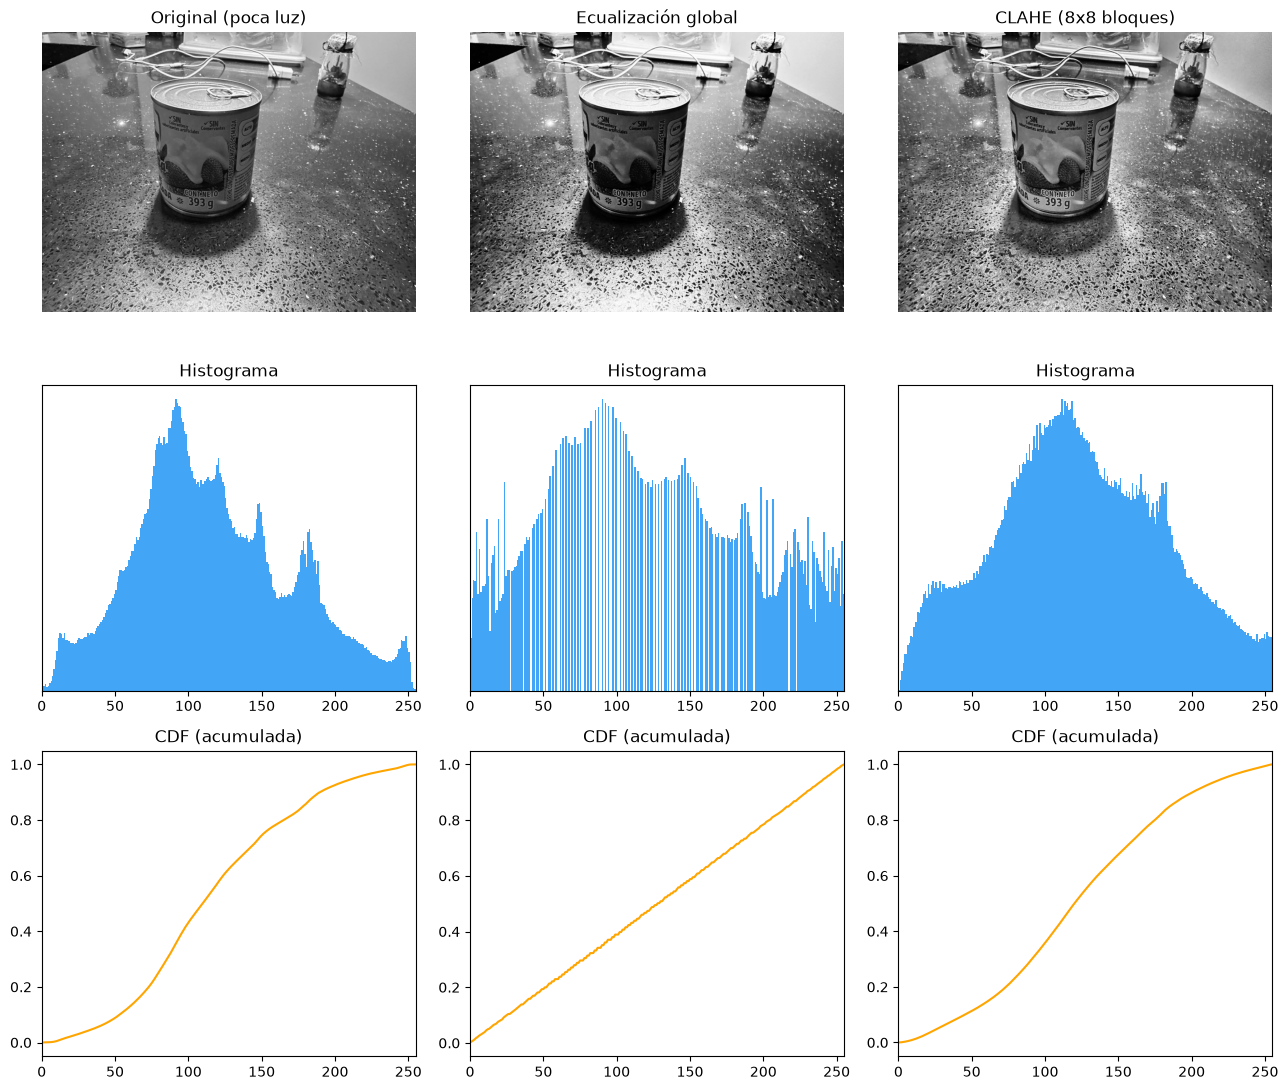

Original    media =  117.0   desviación estándar (contraste) =  52.7
Ecualizada  media =  128.2   desviación estándar (contraste) =  73.5
CLAHE       media =  123.3   desviación estándar (contraste) =  57.1


In [ ]:
gris_oscura = cv2.cvtColor(imagen, cv2.COLOR_RGB2GRAY)

hist = np.bincount(gris_oscura.ravel(), minlength=256)
cdf = hist.cumsum()
cdf_min = cdf[cdf > 0][0]
tabla = np.round((cdf - cdf_min) / (gris_oscura.size - cdf_min) * 255).clip(0, 255).astype(np.uint8)
ecualizada_manual = tabla[gris_oscura]  # cada nivel v se reemplaza por tabla[v]
ecualizada = cv2.equalizeHist(gris_oscura)
print("Diferencia máxima ecualización manual vs cv2.equalizeHist:",
    np.abs(ecualizada_manual.astype(int) - ecualizada.astype(int)).max())

# CLAHE: ecualización por bloques con límite de contraste (evita amplificar ruido)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gris_oscura)

fig, ejes = plt.subplots(3, 3, figsize=(13, 11))
for c, (img, nombre) in enumerate([(gris_oscura, "Original (poca luz)"),
                                (ecualizada, "Ecualización global"), (clahe, "CLAHE (8x8 bloques)")]):
    ejes[0, c].imshow(img, cmap="gray", vmin=0, vmax=255)
    ejes[0, c].set_title(nombre)
    ejes[0, c].axis("off")
    histograma(ejes[1, c], img, "Histograma")
    cdf_img = np.bincount(img.ravel(), minlength=256).cumsum()
    ejes[2, c].plot(cdf_img / cdf_img[-1], color="orange")
    ejes[2, c].set_title("CDF (acumulada)")
    ejes[2, c].set_xlim(0, 255)
plt.tight_layout()
plt.show()
for nombre, img in [("Original", gris_oscura), ("Ecualizada", ecualizada), ("CLAHE", clahe)]:
    print(f"{nombre:<11} media = {img.mean():6.1f}   desviación estándar (contraste) = {img.std():5.1f}")

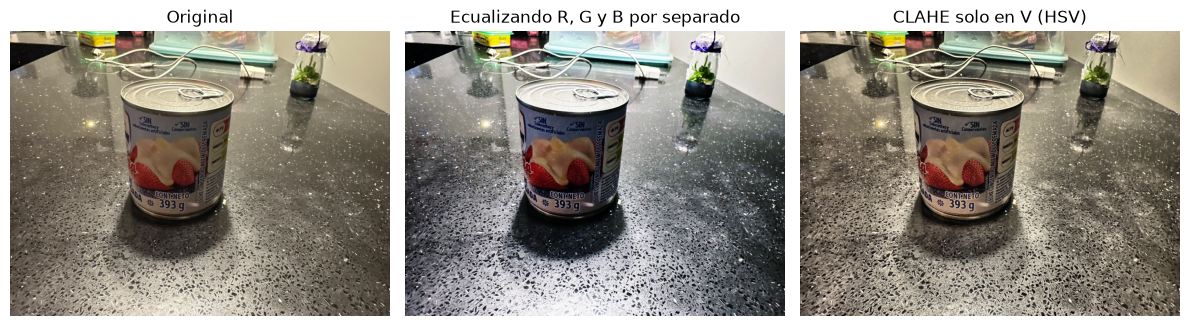

In [13]:
hsv = cv2.cvtColor(imagen_rgb, cv2.COLOR_RGB2HSV)
hsv_v = hsv.copy()
hsv_v[..., 2] = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(hsv[..., 2])
color_v = cv2.cvtColor(hsv_v, cv2.COLOR_HSV2RGB)
por_canal = np.dstack([cv2.equalizeHist(imagen_rgb[..., i]) for i in range(3)])
mostrar([imagen_rgb, por_canal, color_v],
        ["Original", "Ecualizando R, G y B por separado", "CLAHE solo en V (HSV)"])